# Entrenamiento de Transformers
En este Noteebok entrenamos los modelos predictivos que usaremos en el resto de la experimentación, en algunos modelos hemos guardado todos los checkpoints para realizar la técnica **TracIn**.

Se usan tres arquitecturas y tres datasets distintos, dando lugar a 9 modelos

## Preprocesado de datos

Primero cargamos algunas librerías

In [4]:
from datasets import load_dataset, Image
from PIL import Image as PILImage
from io import BytesIO
import matplotlib.pyplot as plt
from collections import Counter
import os
import sys
from huggingface_hub import login
from huggingface_hub import HfApi
import os
import pandas as pd
import numpy as np
from datasets import Image
from transformers import TrainerCallback
import gc
import torch
import evaluate
from transformers import (
    AutoImageProcessor, AutoModelForImageClassification,
    TrainingArguments, Trainer, DefaultDataCollator
)
from transformers import EarlyStoppingCallback
from transformers import TrainerCallback
from torch import nn
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, recall_score, matthews_corrcoef



/home/osniro/test/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Vamos a usar 3 datasets, `PAD-UFES`, `fitzpatrick_stratified_ninelabel_scale` y `PH2`, así que los cargamos y hacemos un (breve) análisis exploratorio

In [ ]:
data1 = load_dataset("z72pepee/skin-gan-review-baseline", "PAD-UFES", token="mi_token")

In [6]:
print(data1)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 2068
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 115
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 115
    })
})


In [ ]:
data2 = load_dataset("z72pepee/skin-gan-review-baseline", "fitzpatrick_stratified_ninelabel_scale", token="mi_token")

In [8]:
print(data2)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 14865
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 826
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 826
    })
})


Creamos la siguiente función para ver el balance de clases y otras características

In [ ]:
data3 = load_dataset("z72pepee/skin-gan-review-baseline", "PH2", token="mi_token")

In [10]:
def analizar_dataset(dataset, split='train', nombre_dataset="Dataset"):
    """
    Analiza un dataset de imágenes de Hugging Face.

    Parámetros:
    - dataset: El objeto del dataset de Hugging Face (ej. data1 o data2).
    - split: La partición a analizar (por defecto 'train').
    - nombre_dataset: Nombre descriptivo para los gráficos y mensajes (opcional).
    """
    print(f"==================================================")
    print(f"        INICIANDO ANÁLISIS: {nombre_dataset.upper()}")
    print(f"==================================================\n")

    # 1. EXTRAER NOMBRES DE LAS CLASES
    try:
        nombres_clases = dataset[split].features['label'].names
        print(f" Clases detectadas ({len(nombres_clases)}): {nombres_clases}\n")
    except AttributeError:
        print(" El dataset no tiene nombres de clases explícitos. Se usarán números.\n")
        nombres_clases = None

    # 2. BALANCEO DE CLASES
    etiquetas = dataset[split]['label']
    conteo_clases = Counter(etiquetas)

    print(f"--- Distribución de imágenes por clase ({split}) ---")
    for clase_id, cantidad in conteo_clases.items():
        nombre = nombres_clases[clase_id] if nombres_clases else clase_id
        print(f"Clase '{nombre}': {cantidad} imágenes")

    # Gráfico de barras del balanceo
    plt.figure(figsize=(10, 5))
    plt.bar(conteo_clases.keys(), conteo_clases.values(), color='#4C72B0')
    plt.title(f'Balance de Clases en {nombre_dataset} ({split})', fontsize=14)
    plt.xlabel('Clases')
    plt.ylabel('Cantidad de imágenes')
    if nombres_clases:
        plt.xticks(ticks=list(conteo_clases.keys()), labels=nombres_clases, rotation=45)
    plt.show()

    # 3. ANÁLISIS DE DIMENSIONES Y CANALES DE COLOR
    lista_imagenes = dataset[split]['image']
    tamanos = set()
    modos_color = set()

    for img in lista_imagenes:
        tamanos.add(img.size) # (ancho, alto)
        modos_color.add(img.mode) # RGB, L, CMYK, RGBA...

    print("\n--- Análisis Físico de las Imágenes ---")
    print(f"Modos de color encontrados: {modos_color}")

    if "RGBA" in modos_color or "L" in modos_color:
        print(" ATENCIÓN: Tienes imágenes que no son RGB estándar. El ImageProcessor tendrá que corregirlo.")

    if len(tamanos) > 5:
        print(f"Tamaños de imagen únicos: {len(tamanos)} (Es normal, el ImageProcessor las redimensionará todas)")
    else:
        print(f"Tamaños encontrados: {tamanos}")

    # 4. INSPECCIÓN VISUAL (Mostrar hasta 4 imágenes aleatorias)
    num_imgs_mostrar = min(4, len(dataset[split]))
    if num_imgs_mostrar > 0:
        fig, axes = plt.subplots(1, num_imgs_mostrar, figsize=(15, 4))

        # Ajuste por si el dataset tiene solo 1 imagen
        if num_imgs_mostrar == 1:
            axes = [axes]

        for i, ax in enumerate(axes):
            img = dataset[split][i]['image']
            label_id = dataset[split][i]['label']
            label_name = nombres_clases[label_id] if nombres_clases else f"Clase {label_id}"

            ax.imshow(img)
            ax.set_title(label_name)
            ax.axis('off')

        plt.suptitle(f"Muestra visual: {nombre_dataset} ({split})", fontsize=14)
        plt.tight_layout()
        plt.show()
    print("\n\n")

        INICIANDO ANÁLISIS: PAD-UFES

 Clases detectadas (6): ['0_ACK', '1_BCC', '2_MEL', '3_NEV', '4_SCC', '5_SEK']

--- Distribución de imágenes por clase (train) ---
Clase '0_ACK': 658 imágenes
Clase '1_BCC': 760 imágenes
Clase '2_MEL': 48 imágenes
Clase '3_NEV': 219 imágenes
Clase '4_SCC': 172 imágenes
Clase '5_SEK': 211 imágenes


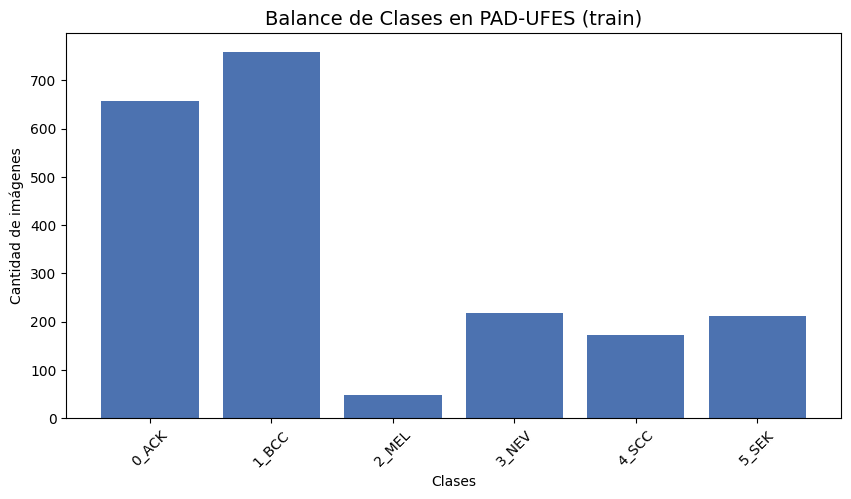


--- Análisis Físico de las Imágenes ---
Modos de color encontrados: {'RGBA', 'RGB'}
 ATENCIÓN: Tienes imágenes que no son RGB estándar. El ImageProcessor tendrá que corregirlo.
Tamaños encontrados: {(224, 224)}


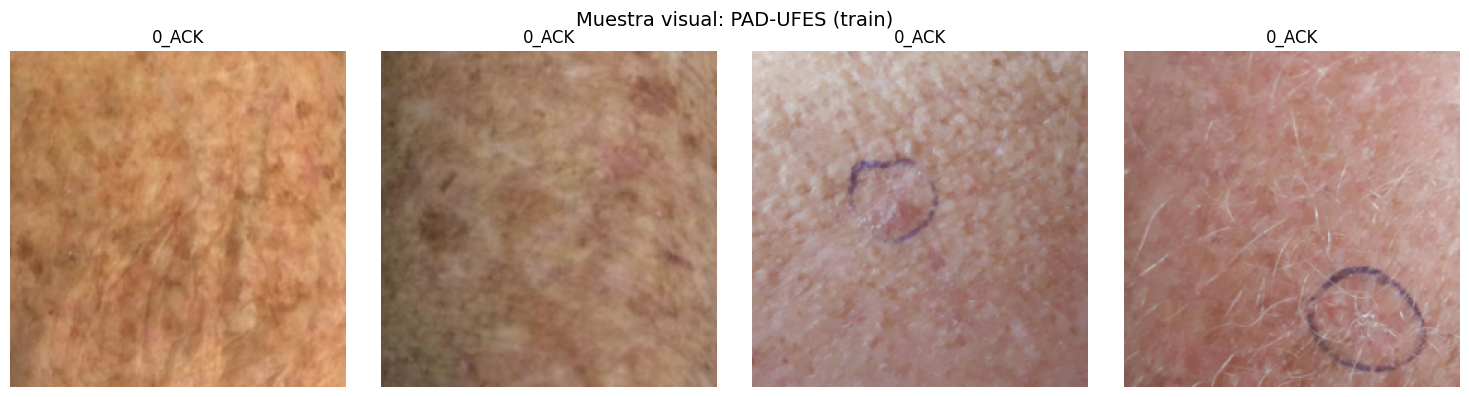

In [11]:
analizar_dataset(data1, nombre_dataset="PAD-UFES")

        INICIANDO ANÁLISIS: FITZPATRICK_STRATIFIED_NINELABEL_SCALE

 Clases detectadas (9): ['000_benign_dermal', '001_benign_epidermal', '002_benign_melanocyte', '003_genodermatoses', '004_inflammatory', '005_malignant_cutaneous_lymphoma', '006_malignant_dermal', '007_malignant_epidermal', '008_malignant_melanoma']

--- Distribución de imágenes por clase (train) ---
Clase '000_benign_dermal': 959 imágenes
Clase '001_benign_epidermal': 838 imágenes
Clase '002_benign_melanocyte': 209 imágenes
Clase '003_genodermatoses': 1067 imágenes
Clase '004_inflammatory': 9755 imágenes
Clase '005_malignant_cutaneous_lymphoma': 166 imágenes
Clase '006_malignant_dermal': 141 imágenes
Clase '007_malignant_epidermal': 1217 imágenes
Clase '008_malignant_melanoma': 513 imágenes


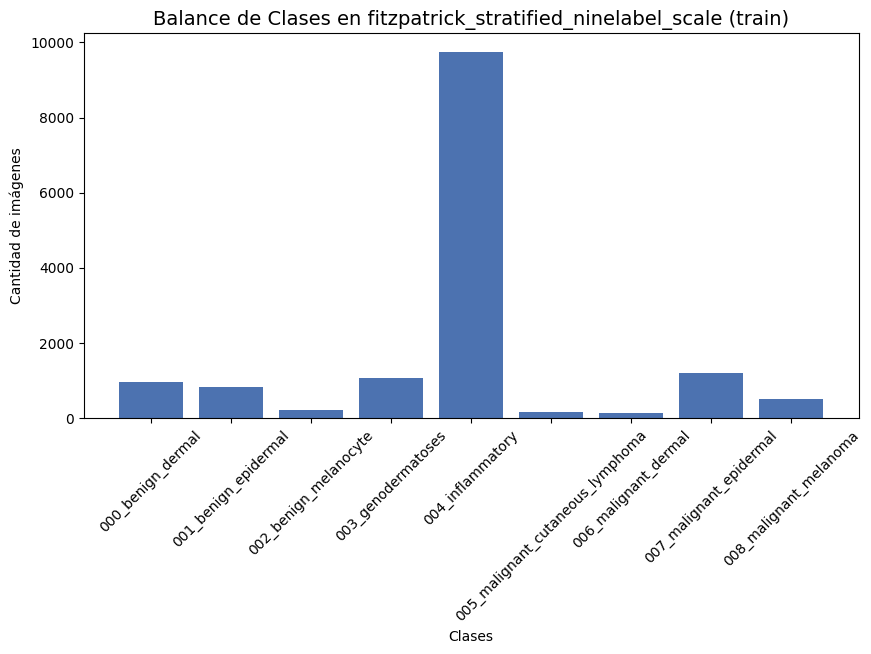


--- Análisis Físico de las Imágenes ---
Modos de color encontrados: {'RGB'}
Tamaños encontrados: {(224, 224)}


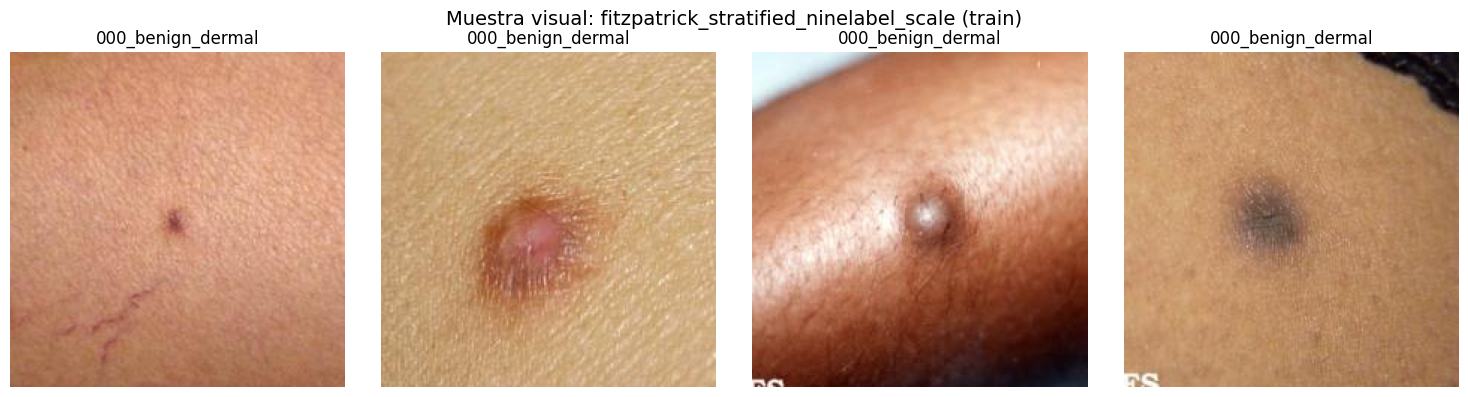

In [12]:
analizar_dataset(data2, nombre_dataset= "fitzpatrick_stratified_ninelabel_scale")

        INICIANDO ANÁLISIS: PH2

 Clases detectadas (2): ['benign', 'malignant']

--- Distribución de imágenes por clase (train) ---
Clase 'benign': 128 imágenes
Clase 'malignant': 32 imágenes


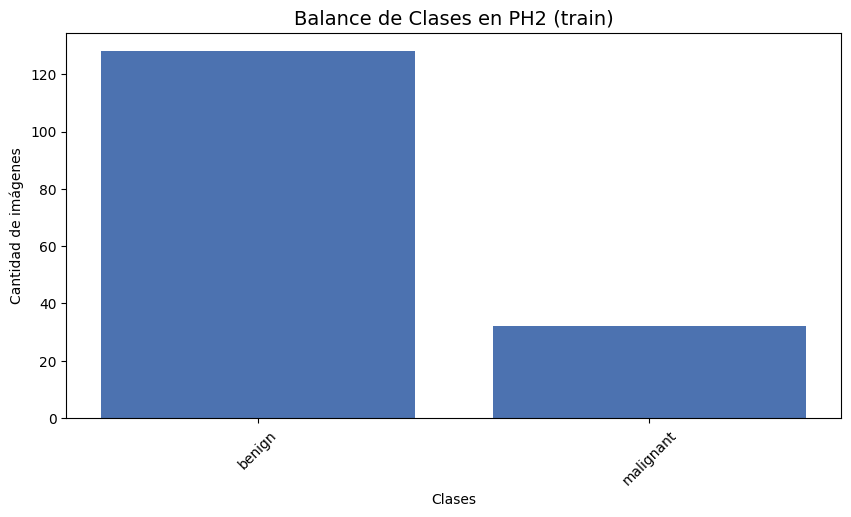


--- Análisis Físico de las Imágenes ---
Modos de color encontrados: {'RGB'}
Tamaños encontrados: {(224, 224)}


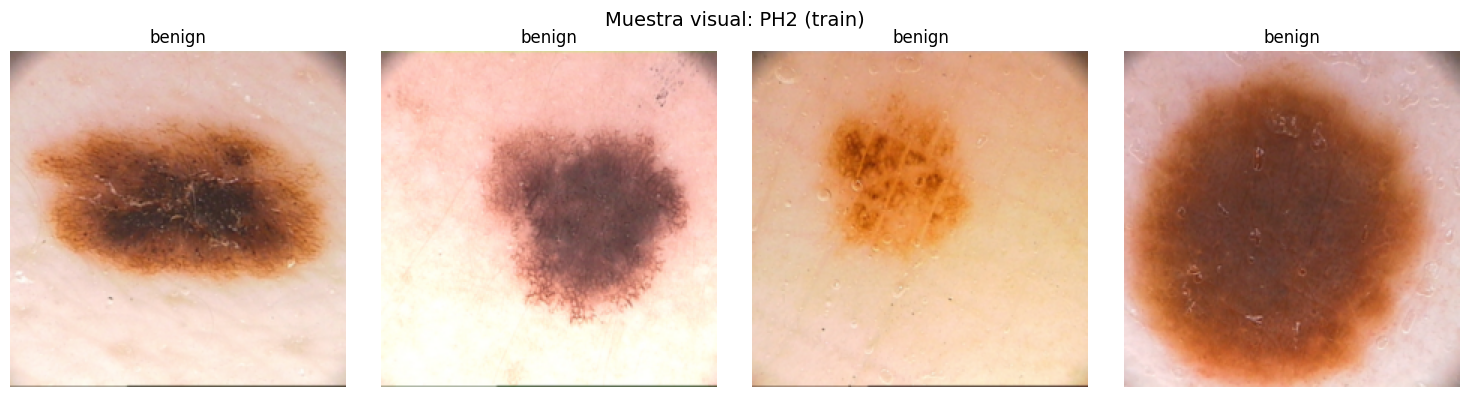

In [13]:
analizar_dataset(data3, nombre_dataset= "PH2")

## Entrenamiento de los ViT

Usaremos tres modelos de ViT (uno de Microsoft, otro de Google y otro de Facebeeok)

In [14]:
# import os
# import sys

# # ==========================================
# # CONFIGURACIÓN GLOBAL
# # ==========================================
# GUARDAR_EN_DRIVE = True
# NOMBRE_CARPETA_PROYECTO = "Modelos_Entrenados"

# if GUARDAR_EN_DRIVE and 'google.colab' in sys.modules:
#     # Estamos en Colab y queremos Drive
#     from google.colab import drive
#     drive.mount('/content/drive')
#     DIRECTORIO_BASE = f"/content/drive/MyDrive/{NOMBRE_CARPETA_PROYECTO}"
# else:
#     # Estamos en local, o en Colab pero sin querer usar Drive
#     DIRECTORIO_BASE = f"./{NOMBRE_CARPETA_PROYECTO}"

# # Nos aseguramos de que la carpeta maestra exista
# os.makedirs(DIRECTORIO_BASE, exist_ok=True)
# print(f" Todos los experimentos se guardarán en: {DIRECTORIO_BASE}")

In [ ]:
# ==========================================
#  CONFIGURACIÓN GLOBAL (Hugging Face Bucket)
# ==========================================

# Iniciamos sesión en Hugging Face

token="mi_token"

api = HfApi(token=token)

bucket_id = "z72pepee/tfm-explicabilidad"


# Definimos la ruta como una carpeta LOCAL temporal en la máquina virtual
DIRECTORIO_BASE = "./Modelos_Entrenados"
os.makedirs(DIRECTORIO_BASE, exist_ok=True)
print(f" Los experimentos se guardarán temporalmente en: {DIRECTORIO_BASE} y se subirán al Bucket.")

 Los experimentos se guardarán temporalmente en: ./Modelos_Entrenados y se subirán al Bucket.


In [18]:
class TodasLasPrediccionesCallback(TrainerCallback):
    """
    Evalúa Train, Val y Test al final de cada época y guarda las predicciones NUMÉRICAS
    en tres archivos separados (train.csv, val.csv, test.csv) añadiendo una columna por época.
    """
    def __init__(self, trainer, dict_datasets_eval, dict_datasets_original, carpeta_base):
        self.trainer = trainer
        self.dict_datasets_eval = dict_datasets_eval
        self.carpeta_base = carpeta_base

        self.nombres_archivos = {
            "train": "train.csv",
            "validation": "val.csv",
            "test": "test.csv"
        }

        # Inicializamos los 3 DataFrames
        self.dataframes = {}

        for split in ["train", "validation", "test"]:
            # Sacamos los nombres de las imágenes crudas
            dataset_meta = dict_datasets_original[split].cast_column("image", Image(decode=False))
            nombres = []
            for example in dataset_meta:
                ruta = example["image"]["path"]
                nombres.append(os.path.basename(ruta) if ruta else "Desconocido")

            # El profesor quiere NÚMEROS, así que dejamos la etiqueta real como número
            etiquetas_reales = dict_datasets_original[split]["label"]

            self.dataframes[split] = pd.DataFrame({
                "nombre_imagen": nombres,
                "etiqueta_real": etiquetas_reales
            })

    def on_epoch_end(self, args, state, control, **kwargs):
        epoca_actual = int(state.epoch)
        print(f"\n [Callback] Generando predicciones de TODOS los conjuntos para la Época {epoca_actual}...")

        for split in ["train", "validation", "test"]:
            # Predecimos
            salida = self.trainer.predict(self.dict_datasets_eval[split])

            # Sacamos el NÚMERO de la clase ganadora
            predicciones_numericas = np.argmax(salida.predictions, axis=1)

            # Añadimos la nueva columna
            self.dataframes[split][f"epoca_{epoca_actual}"] = predicciones_numericas

            # Sobreescribimos el CSV actualizado en Drive
            ruta_csv = f"{self.carpeta_base}/{self.nombres_archivos[split]}"
            self.dataframes[split].to_csv(ruta_csv, index=False)

        print(f"   Archivos train.csv, val.csv y test.csv actualizados.")


In [19]:
class LossLoggingCallback(TrainerCallback):
    def __init__(self, ruta_archivo_csv):
        self.ruta_archivo_csv = ruta_archivo_csv
        if os.path.exists(self.ruta_archivo_csv):
            os.remove(self.ruta_archivo_csv)

    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs is not None:
            logs["epoch"] = state.epoch
            logs["step"] = state.global_step
            df_nuevo = pd.DataFrame([logs])
            header = not os.path.exists(self.ruta_archivo_csv)
            df_nuevo.to_csv(self.ruta_archivo_csv, mode='a', header=header, index=False)

In [20]:
# Precargar las métricas fuera de la función para no descargarlas en cada experimento
mcc_metric = evaluate.load("matthews_correlation")
f1_metric = evaluate.load("f1")

def entrenar_experimento(dataset_cargado, checkpoint_modelo, nombre_experimento,ruta_base):
    print(f"\n{'='*50}")
    print(f" INICIANDO EXPERIMENTO: {nombre_experimento}")
    print(f"Modelo: {checkpoint_modelo}")
    print(f"{'='*50}\n")

    # Preparar etiquetas
    etiquetas = dataset_cargado["train"].features["label"].names
    id2label = {str(i): label for i, label in enumerate(etiquetas)}
    label2id = {label: str(i) for i, label in enumerate(etiquetas)}

    # Cargar Procesador y Modelo
    processor = AutoImageProcessor.from_pretrained(checkpoint_modelo)
    model = AutoModelForImageClassification.from_pretrained(
        checkpoint_modelo,
        num_labels=len(etiquetas),
        id2label=id2label,
        label2id=label2id,
        ignore_mismatched_sizes=True
    )

    # Transformaciones (Asegura que la imagen siempre pase a RGB, clave para evitar errores)
    def transforma_lote(ejemplos):
        inputs = processor([img.convert("RGB") for img in ejemplos["image"]], return_tensors="pt")
        inputs["labels"] = ejemplos["label"]
        return inputs

    dataset_preparado = dataset_cargado.with_transform(transforma_lote)

    # Métricas actualizadas (MCC y F1 Macro)
    def compute_metrics(eval_pred):
        predicciones_crudas, referencias = eval_pred
        predicciones = np.argmax(predicciones_crudas, axis=1)

        mcc = mcc_metric.compute(predictions=predicciones, references=referencias)["matthews_correlation"]
        f1 = f1_metric.compute(predictions=predicciones, references=referencias, average="macro")["f1"]

        return {"mcc": mcc, "f1_macro": f1}

    # Calculamos los pesos ideales usando Scikit-Learn
    etiquetas_train = dataset_cargado["train"]["label"]
    clases_unicas = np.unique(etiquetas_train)

    # compute_class_weight balancea matemáticamente: (total_muestras / (num_clases * muestras_por_clase))
    pesos_np = compute_class_weight(class_weight='balanced', classes=clases_unicas, y=etiquetas_train)

    # Lo convertimos a tensor para que PyTorch (y la tarjeta gráfica) lo entienda
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    class_weights = torch.tensor(pesos_np, dtype=torch.float32).to(device)

    print(f"\n Pesos de clase calculados: {class_weights}")

    # Creamos nuestro propio Trainer
    class WeightedTrainer(Trainer):
     def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        # Extraemos las etiquetas correctas de las entradas
        labels = inputs.get("labels")

        # Pasamos las imágenes por el modelo
        outputs = model(**inputs)

        # Extraemos las predicciones crudas (logits)
        logits = outputs.get("logits")

        # Definimos nuestra propia función de pérdida con los pesos inyectados
        loss_fct = nn.CrossEntropyLoss(weight=class_weights)

        # Calculamos la pérdida usando nuestras reglas
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))

        return (loss, outputs) if return_outputs else loss


    # Argumentos y Rutas dinámicas
    carpeta_base = f"{ruta_base}/{nombre_experimento}"
    os.makedirs(carpeta_base, exist_ok=True)

    # Rutas de los CSV de los espías
    ruta_csv_predicciones = f"{carpeta_base}/predicciones_test_por_epoca.csv"
    ruta_csv_loss = f"{carpeta_base}/historial_loss.csv"
    # Argumentos y Entrenador
    training_args = TrainingArguments(
        output_dir=carpeta_base,
        remove_unused_columns=False,
        eval_strategy="epoch",      # Evalúa al final de cada época
        save_strategy="epoch",      # Guarda al final de cada época (necesario para el callback y load_best)
        logging_strategy="epoch",
        learning_rate=5e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16, # Buena práctica añadir el tamaño de batch de evaluación
        num_train_epochs=50,

        # --- MEJORAS PARA AHORRO DE ESPACIO Y EARLY STOPPING ---
        load_best_model_at_end=True,
       metric_for_best_model="mcc", # Usamos nuestra nueva métrica para decidir el mejor
        greater_is_better=True,           # El F1, a diferencia del loss, cuanto mayor, mejor
        save_total_limit=None                # Solo mantiene el mejor modelo. Borrará los checkpoints intermedios de épocas peores.
    )

    trainer = WeightedTrainer(
        model=model,
        args=training_args,
        data_collator=DefaultDataCollator(),
        train_dataset=dataset_preparado["train"],

        # --- CAMBIO A VALIDATION ---
        # Evalúa en validation durante el entrenamiento, manteniendo test ciego
        eval_dataset=dataset_preparado["validation"],
        processing_class=processor,
        compute_metrics=compute_metrics,

        # El early stopping ahora mirará el "f1_macro" para decidir si para
    )
    # El callback necesita el trainer ya instanciado en el paso anterior
    callback_predicciones = TodasLasPrediccionesCallback(
        trainer=trainer,
        dict_datasets_eval=dataset_preparado,    # Pasamos el dict entero de tensores
        dict_datasets_original=dataset_cargado,  # Pasamos el dict entero crudo (para nombres)
        carpeta_base=carpeta_base
    )
    callback_loss = LossLoggingCallback(ruta_archivo_csv=ruta_csv_loss)

    # Añadimos los espías al trainer
    trainer.add_callback(EarlyStoppingCallback(early_stopping_patience=5))
    trainer.add_callback(callback_predicciones)
    trainer.add_callback(callback_loss)
    # Entrenar
    trainer.train()


    ## SUBIDA 
    print("\n Entrenamiento terminado. Subiendo el modelo ganador y los CSVs al bucket...")


    # Nos aseguramos de que el trainer guarde el mejor modelo limpiamente
    #trainer.save_model(carpeta_base)

    archivos_a_subir = []
    nombre_exp = carpeta_base.split('/')[-1]

    # Escaneamos la carpeta final
    for raiz, _, ficheros in os.walk(carpeta_base):
        for fichero in ficheros:
            ruta_local = os.path.join(raiz, fichero)
            ruta_relativa = os.path.relpath(ruta_local, carpeta_base)
            ruta_remota = f"Modelos_Entrenados/{nombre_exp}/{ruta_relativa}"
            archivos_a_subir.append((str(ruta_local), ruta_remota))

    try:
        api.batch_bucket_files(
            bucket_id,
            add=archivos_a_subir
        )
        print("Trabajo terminado y subido al bucket")
    except Exception as e:
        print(f" Error al subir al bucket: {e}")

    # EVALUACIÓN FINAL COMPARATIVA
    print("\n Ejecutando evaluación final comparativa (Validación vs Test)...")

    splits_a_evaluar = {
        "Validación": dataset_preparado["validation"],
        "Test": dataset_preparado["test"]
    }

    resultados = {}

    # Extraemos la lista de IDs exactos (ej: [0, 1, 2, 3, 4, 5])
    todas_las_clases = list(range(len(id2label)))

    for nombre_split, dataset_split in splits_a_evaluar.items():
        salida = trainer.predict(dataset_split)
        predicciones = np.argmax(salida.predictions, axis=1)
        etiquetas_reales = salida.label_ids

        resultados[nombre_split] = {
            "acc": accuracy_score(etiquetas_reales, predicciones),
            "mcc": matthews_corrcoef(etiquetas_reales, predicciones),
            "f1_macro": f1_score(etiquetas_reales, predicciones, average="macro", zero_division=0),
            "f1_weighted": f1_score(etiquetas_reales, predicciones, average="weighted", zero_division=0),
            "recall": recall_score(etiquetas_reales, predicciones, average=None, labels=todas_las_clases, zero_division=0)
        }

    # Imprimimos la tabla
    print("\n" + "═"*65)
    print(f" COMPARATIVA FINAL: VALIDACIÓN vs TEST")
    print("═"*65)
    print(f"{'Métrica':<15} | {'Validación':<20} | {'Test':<20}")
    print("-" * 65)
    print(f"{'Accuracy':<15} | {resultados['Validación']['acc']:.4f} {'':<12}| {resultados['Test']['acc']:.4f}")
    print(f"{'MCC':<15} | {resultados['Validación']['mcc']:.4f} {'':<12}| {resultados['Test']['mcc']:.4f}")
    print(f"{'F1 Macro':<15} | {resultados['Validación']['f1_macro']:.4f} {'':<12}| {resultados['Test']['f1_macro']:.4f}")
    print(f"{'F1 Weighted':<15} | {resultados['Validación']['f1_weighted']:.4f} {'':<12}| {resultados['Test']['f1_weighted']:.4f}")
    print("-" * 65)
    print("Recall por clase (capacidad de detectar cada categoría):")
    print("-" * 65)

    # Bucle iterando SOLO por el número de clases reales
    for id_clase in todas_las_clases:
        nombre = id2label[str(id_clase)]
        rec_val = resultados['Validación']['recall'][id_clase]
        rec_test = resultados['Test']['recall'][id_clase]

        texto_val = f"{rec_val:.4f} ({rec_val*100:>4.1f}%)"
        texto_test = f"{rec_test:.4f} ({rec_test*100:>4.1f}%)"

        print(f" • {nombre:<12} | {texto_val:<20} | {texto_test}")
    print("═"*65 + "\n")



    # ==========================================
    #  LIMPIEZA
    # ==========================================
    print(f"\nTerminado {nombre_experimento}. Limpiando memoria...")
    del model
    del trainer
    del dataset_preparado
    torch.cuda.empty_cache()
    gc.collect()
    print("Memoria liberada. Listo para el siguiente.\n")

### Primer modelo (microsoft)

In [ ]:
entrenar_experimento(data1, "microsoft/beit-base-patch16-224", "experimento_dataset1_microsoft",DIRECTORIO_BASE)


 INICIANDO EXPERIMENTO: experimento_dataset1_microsoft
Modelo: microsoft/beit-base-patch16-224



[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `1000`.
Loading weights: 100%|██████████| 223/223 [00:00<00:00, 370.41it/s]
[transformers] BeitForImageClassification LOAD REPORT from: microsoft/beit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([6, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([6])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[RANK 0] Detected kernel version 4.15.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upg


 Pesos de clase calculados: tensor([0.5238, 0.4535, 7.1806, 1.5738, 2.0039, 1.6335], device='cuda:0')


Epoch,Training Loss,Validation Loss,Mcc,F1 Macro,
1,1.308677,0.839795,0.560997,0.601658,130
2,0.853353,0.744923,0.649525,0.687596,260



 [Callback] Generando predicciones de TODOS los conjuntos para la Época 1...
   Archivos train.csv, val.csv y test.csv actualizados.


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.33it/s]



 [Callback] Generando predicciones de TODOS los conjuntos para la Época 2...
   Archivos train.csv, val.csv y test.csv actualizados.


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.30it/s]


In [ ]:
#entrenar_experimento(data2, "microsoft/beit-base-patch16-224", "experimento_dataset2_microsoft",DIRECTORIO_BASE)

In [ ]:
# entrenar_experimento(data3, "microsoft/beit-base-patch16-224", "experimento_dataset3_microsoft",DIRECTORIO_BASE)

### Segundo modelo

In [ ]:
# entrenar_experimento(data1, "google/vit-base-patch16-224", "experimento_dataset1_googleViT",DIRECTORIO_BASE)


In [ ]:
# entrenar_experimento(data2, "google/vit-base-patch16-224", "experimento_dataset2_googleViT",DIRECTORIO_BASE)


In [ ]:
entrenar_experimento(data3, "google/vit-base-patch16-224", "experimento_dataset3_googleViT",DIRECTORIO_BASE)

### Tercer modelo

In [ ]:
#entrenar_experimento(data1, "facebook/dinov2-base-imagenet1k-1-layer", "experimento_dataset1_facebook_dinov2",DIRECTORIO_BASE)


In [ ]:
 entrenar_experimento(data2, "facebook/dinov2-base-imagenet1k-1-layer", "experimento_dataset2_facebook_dinov2",DIRECTORIO_BASE)

In [ ]:
# entrenar_experimento(data3, "facebook/dinov2-base-imagenet1k-1-layer", "experimento_dataset3_facebook_dinov2",DIRECTORIO_BASE)